# Are Polymarket prices calibrated?

When a market's price says **70%**, does the event happen about **70%** of the time? If it does at every price level, the market is *calibrated*: its prices can be read as honest probabilities.

This notebook answers that with the data in the local PostgreSQL database (download → normalize → snapshots → load). For every market we use its price at **1, 7 and 30 days before it closed**, never the final price, which already knows the answer.

**How to read a calibration chart**
- Each dot is a group of markets with similar prices (for example all markets priced 60–70%).
- **x** = their average price, **y** = how often the first outcome (e.g. "Yes") actually happened.
- **On the diagonal** = calibrated. **Above** = it happened more often than the price said (price too low). **Below** = price too high.
- The vertical bars are 95% confidence intervals: with fewer markets in a group, the bar is longer.

In [1]:
import pandas as pd
import plotly.io as pio

from analysis.calibration import (
    calibration_figure, calibration_table, load_calibration_data, same_markets_only, scores,
)

# Interactive charts in VS Code, plus a static image so they also show on GitHub
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 1200, 420

data = load_calibration_data()
print(f"{len(data):,} snapshots from {data['market_id'].nunique():,} markets in {data['event_id'].nunique():,} events")

20,845 snapshots from 10,723 markets in 6,305 events


## 1. The calibration curves

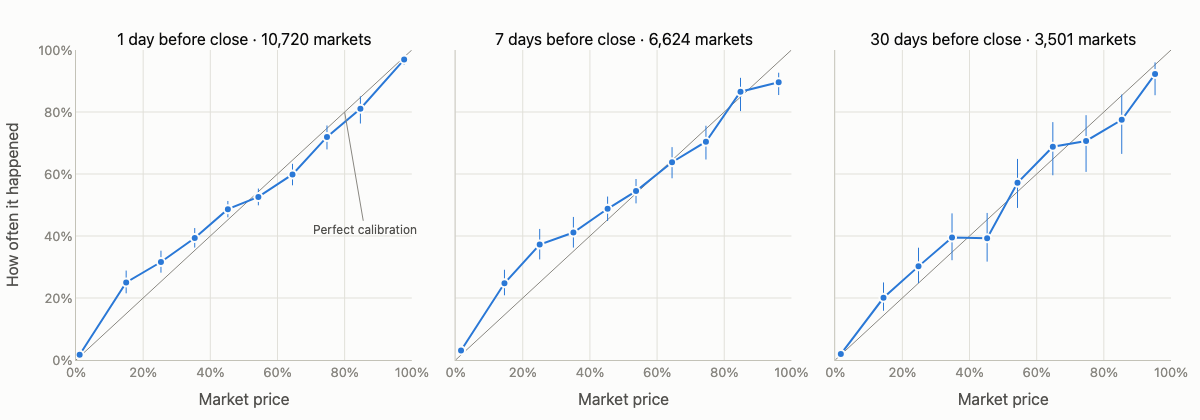

In [2]:
table = calibration_table(data)
calibration_figure(table).show()

The same numbers as a table: how many markets, their average price, and how often the first outcome happened.

In [3]:
in_percent = table.assign(avg_price_pct=table["avg_price"] * 100, happened_pct=table["happened_rate"] * 100).round(1)
in_percent.pivot(index="bin_label", columns="horizon_days", values=["markets", "avg_price_pct", "happened_pct"])

markets                 avg_price_pct             happened_pct  \
horizon_days      1       7       30            1     7     30           1    
bin_label                                                                     
0–10%         3721.0  3181.0  2138.0           1.1   1.6   1.7          1.7   
10–20%         532.0   420.0   294.0          14.9  14.5  14.4         25.0   
20–30%         658.0   368.0   245.0          25.3  25.0  24.8         31.6   
30–40%         922.0   377.0   157.0          35.4  35.1  34.8         39.4   
40–50%        1379.0   615.0   145.0          45.2  45.3  45.2         48.7   
50–60%        1304.0   613.0   147.0          54.3  53.7  54.3         52.6   
60–70%         765.0   348.0   109.0          64.5  64.5  64.8         59.9   
70–80%         517.0   267.0    92.0          74.7  74.6  74.7         72.0   
80–90%         306.0   156.0    71.0          84.7  84.8  85.3         81.0   
90–100%        616.0   279.0   103.0          97.7  96.2  95.3         96.9   

                          
horizon_days    7     30  
bin_label                 
0–10%          3.0   1.9  
10–20%        24.8  20.1  
20–30%        37.2  30.2  
30–40%        41.1  39.5  
40–50%        48.8  39.3  
50–60%        54.5  57.1  
60–70%        63.8  68.8  
70–80%        70.4  70.7  
80–90%        86.5  77.5  
90–100%       89.6  92.2

## 2. How accurate are the prices overall?

Three scores per horizon:
- **Brier score**: the average of (price − outcome)². 0 is perfect; lower is better.
- **Brier skill**: how much better than always guessing the overall base rate. 1 = perfect, 0 = no better than that naive guess.
- **Calibration error**: the average gap between price and how often things happened, weighted by group size, in percentage points (0 = perfectly calibrated).

To compare horizons fairly we use **only markets that have all three snapshots**. Otherwise the 1-day group also contains thousands of short markets (e.g. sports games, which are close to coin flips the day before), and the comparison would be about *different markets*, not different horizons.

In [4]:
same = same_markets_only(data)
fair = scores(same)
fair[["base_rate", "calibration_error"]] = (fair[["base_rate", "calibration_error"]] * 100).round(1)  # in %
fair.round(3).rename(columns={"base_rate": "base_rate_%", "calibration_error": "calibration_error_%"})

,horizon_days,markets,events,base_rate_%,brier,brier_skill,calibration_error_%
0,1,3499,1193,19.1,0.046,0.704,1.2
1,7,3499,1193,19.1,0.067,0.569,1.9
2,30,3499,1193,19.1,0.089,0.425,2.1


## 3. Is one big event driving the pattern?

Markets in the same event are related (an election with 20 candidates is 20 markets that resolve together), so the confidence intervals above are too narrow. As a check, we weight each market by 1 / (markets in its event), so **every event counts once**, and look at the low-price groups where the curves sit above the diagonal.

In [5]:
weighted = data.assign(
    weight=1 / data.groupby(["horizon_days", "event_id"])["market_id"].transform("size"),
    bin=lambda d: (d["price"] * 10).astype(int).clip(upper=9),
)
low = weighted[weighted["bin"].isin([1, 2])]  # priced 10-30%
check = low.groupby(["horizon_days", "bin"]).apply(
    lambda g: pd.Series({
        "events (weighted)": g["weight"].sum(),
        "avg_price": (g["price"] * g["weight"]).sum() / g["weight"].sum(),
        "happened_rate": (g["outcome"] * g["weight"]).sum() / g["weight"].sum(),
    }),
    include_groups=False,
)
check[["avg_price", "happened_rate"]] = (check[["avg_price", "happened_rate"]] * 100).round(1)  # in %
check.round({"events (weighted)": 0}).rename(columns={"avg_price": "avg_price_%", "happened_rate": "happened_%"})

events (weighted)  avg_price_%  happened_%
horizon_days bin                                            
1            1                305.0         15.3        24.3
             2                426.0         25.3        32.2
7            1                172.0         14.8        32.3
             2                187.0         25.2        40.2
30           1                121.0         14.6        22.5
             2                106.0         24.8        36.5

## 4. What we found

*Numbers from the data downloaded on 2026-10-16: 10,792 resolved markets with ≥ $1M volume.*

1. **Polymarket is broadly well calibrated.** On the 3,499 markets with all three snapshots, the average gap between price and reality is only 1.2, 1.9 and 2.1 percentage points at 1, 7 and 30 days before close (section 2).
2. **Prices get more accurate as the close approaches.** On those same markets the Brier score falls from 0.089 (30 days) to 0.067 (7 days) to 0.046 (1 day), and skill rises from 0.425 to 0.569 to 0.704.
3. **The clearest bias: outcomes priced 10–30% happen more often than their price says.** Markets priced 10–20% one day before close averaged 14.9% but happened 25.0% of the time (532 markets); at 7 days it was 14.5% vs 24.8%. One day before close the pattern runs across the whole curve: **every** price group below 50% happened more often than its average price, and **every** group above 50% happened less often (e.g. priced 64.5% on average, happened 59.9%). In other words, prices are a little *too far from 50%*: too confident in both directions. This is the reverse of the classic *favorite–longshot bias*, where unlikely outcomes are overpriced.
4. **The pattern holds when every event counts once** (section 3), so it isn't caused by a few big events with many related markets.

## Caveats

- **Which markets:** only resolved markets with ≥ $1M volume, ending from July 2020, open at least 1 day. Smaller markets could behave differently.
- **Related markets:** markets in the same event aren't independent, so the true uncertainty is wider than the confidence bars show. Section 3 is a check, not a full fix.
- **"Outcome" means the first listed outcome**, e.g. "Yes", or the first team in "Team A vs Team B". Every market has two sides, so the chart is the same data seen from one side.
- **No topic split yet:** Polymarket leaves `category` empty for almost all markets, so we can't yet compare e.g. sports vs politics. That is the obvious next question, especially for finding 3.
- **Prices aren't trades:** we use the price-history API's price; a real trader would also pay the bid–ask spread and fees.